<a href="https://colab.research.google.com/github/masumeaslanii/ML2026/blob/main/Exe1_overfitting_problem/final_50epochs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import time
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, Subset
from torchvision import transforms, datasets
import copy

## What do we do for implementing 2D CNN on our Dataset?

* Connecting to our Drive
* Loading our dataset
* Creating batch sets
* Defining device
* Designing our CNN model
* Train and validation loop
* Saving and Loading our model
* predicting on unseen data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
DATA_DIR= '/content/drive/MyDrive/CIFAR100_Dataset'

In [ ]:
x = torch.stack([transforms.ToTensor()(img) for img, _ in datasets.CIFAR100(DATA_DIR, train=True, download=False)])
print(x.mean(dim=(0, 2, 3)), x.std(dim=(0, 2, 3)))

tensor([0.5071, 0.4866, 0.4409]) tensor([0.2673, 0.2564, 0.2762])


In [ ]:
mean, std = x.mean(dim=(0, 2, 3)), x.std(dim=(0, 2, 3))

train_transform = transforms.Compose([transforms.RandomCrop(32, padding= 4),
                                      transforms.RandomHorizontalFlip(),
                                      transforms.ToTensor(),
                                      transforms.Normalize(mean= mean, std= std)])




test_transform = transforms.Compose([transforms.ToTensor(),
                                    transforms.Normalize(mean= mean, std= std)])

In [ ]:
traindata = datasets.CIFAR100(root= DATA_DIR,
                              train= True,
                              download= False,
                              transform= train_transform)

validationdata = datasets.CIFAR100(root= DATA_DIR,
                              train= True,
                              download= False,
                              transform= test_transform)

testdata = datasets.CIFAR100(root= DATA_DIR,
                              train= False,
                              download= False,
                              transform= test_transform)

In [ ]:
traindata, validationdata, testdata

(Dataset CIFAR100
     Number of datapoints: 50000
     Root location: /content/drive/MyDrive/CIFAR100_Dataset
     Split: Train
     StandardTransform
 Transform: Compose(
                RandomCrop(size=(32, 32), padding=4)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
                Normalize(mean=tensor([0.5071, 0.4866, 0.4409]), std=tensor([0.2673, 0.2564, 0.2762]))
            ),
 Dataset CIFAR100
     Number of datapoints: 50000
     Root location: /content/drive/MyDrive/CIFAR100_Dataset
     Split: Train
     StandardTransform
 Transform: Compose(
                ToTensor()
                Normalize(mean=tensor([0.5071, 0.4866, 0.4409]), std=tensor([0.2673, 0.2564, 0.2762]))
            ),
 Dataset CIFAR100
     Number of datapoints: 10000
     Root location: /content/drive/MyDrive/CIFAR100_Dataset
     Split: Test
     StandardTransform
 Transform: Compose(
                ToTensor()
                Normalize(mean=tensor([0.5071, 0.4866, 0.4409]), std

In [ ]:
type(traindata[49999][0])

torch.Tensor

In [ ]:
train_label = traindata.targets


In [ ]:
train_image= traindata.data
train_image[49999].shape, type(train_image[49999])

((32, 32, 3), numpy.ndarray)

array([[[141, 134, 115],
        [167, 160, 142],
        [161, 154, 137],
        ...,
        [ 59,  49,  38],
        [ 44,  34,  23],
        [ 80,  70,  60]],

       [[107,  99,  85],
        [146, 139, 121],
        [153, 147, 124],
        ...,
        [ 40,  30,  18],
        [103,  94,  81],
        [165, 155, 143]],

       [[ 71,  64,  49],
        [112, 105,  87],
        [120, 114,  91],
        ...,
        [ 96,  87,  72],
        [154, 145, 130],
        [180, 170, 155]],

       ...,

       [[119, 112,  94],
        [ 92,  86,  68],
        [ 79,  72,  54],
        ...,
        [147, 138, 121],
        [ 95,  86,  69],
        [ 59,  50,  33]],

       [[130, 122, 104],
        [114, 107,  89],
        [ 84,  77,  59],
        ...,
        [ 71,  62,  45],
        [ 52,  43,  26],
        [ 81,  72,  55]],

       [[141, 133, 115],
        [122, 115,  98],
        [106,  99,  81],
        ...,
        [ 66,  57,  40],
        [ 98,  89,  72],
        [140, 131, 114]]], shape=(32, 32, 3), dtype=uint8)
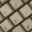

In [ ]:
train_image[4999]

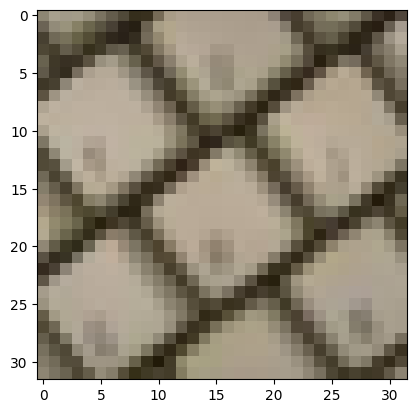

In [ ]:
plt.imshow(train_image[4999])

In [ ]:
train_image.shape[0]

50000

In [ ]:
generator = torch.Generator().manual_seed(42)
indices= torch.randperm(train_image.shape[0], generator= generator)
indices

tensor([37542, 44491,   216,  ..., 40730, 25847, 33082])

In [ ]:
train_indices = indices[:45000].tolist()
validaion_indices = indices[45000:].tolist()
type(train_indices)

list

In [ ]:
train_data = Subset(traindata, train_indices)
val_data = Subset(validationdata, validaion_indices)

In [ ]:
TrainLoader = DataLoader(train_data, batch_size= 128, shuffle= True)
TestLoader = DataLoader(testdata, batch_size= 128, shuffle= False)
ValidationLoader = DataLoader(val_data, batch_size= 128, shuffle= False)

## Defining device

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

## Designing our 2D CNN Model

In [ ]:
class CNN2D(nn.Module):
  def __init__(self, in_channel, num_classes):
    super(CNN2D, self).__init__()


    self.Blocks = nn.Sequential(nn.Conv2d(in_channels= in_channel, out_channels= 64,
                                          kernel_size = 3, padding= 1, stride= 1),
                                nn.BatchNorm2d(num_features= 64),
                                nn.ReLU(inplace= False),
                                nn.MaxPool2d(kernel_size= 2, stride= 2),

                                nn.Conv2d(in_channels= 64, out_channels= 128,
                                          kernel_size = 3, padding= 1, stride= 1),
                                nn.BatchNorm2d(num_features= 128),
                                nn.ReLU(inplace= False),
                                nn.MaxPool2d(kernel_size= 2, stride= 2),

                                nn.Conv2d(in_channels= 128, out_channels= 256,
                                          kernel_size = 3, padding= 1, stride= 1),
                                nn.BatchNorm2d(num_features= 256),
                                nn.ReLU(inplace= False),
                                nn.MaxPool2d(kernel_size= 2, stride= 2))

    self.FC = nn.Sequential(nn.Flatten(),
                            nn.Linear(256*4*4, 128),
                            nn.ReLU(),
                            nn.Dropout(p= 0.2),
                            nn.Linear(128, num_classes))


  def forward(self, x):
    x = self.Blocks(x)
    x = self.FC(x)

    return x

In [ ]:
torch.manual_seed(42)

CNN_Model = CNN2D(3, 100).to(device)
CNN_Model


CNN2D(
  (Blocks): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (FC): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): 

In [ ]:
total_para = sum(p.numel() for p in CNN_Model.parameters())
total_para

909028

In [ ]:
CNN_Model.state_dict()

OrderedDict([('Blocks.0.weight',
              tensor([[[[ 0.1471,  0.1597, -0.0451],
                        [ 0.1768, -0.0422,  0.0388],
                        [-0.0937,  0.1130,  0.1697]],
              
                       [[-0.1412,  0.1673,  0.0360],
                        [ 0.1422,  0.0261,  0.0928],
                        [-0.0272,  0.1484,  0.0284]],
              
                       [[-0.0898,  0.0491, -0.0887],
                        [-0.0226, -0.0782,  0.1277],
                        [-0.1519, -0.0887, -0.0543]]],
              
              
                      [[[-0.1157,  0.0182, -0.1901],
                        [ 0.1738, -0.1635,  0.1486],
                        [ 0.0320, -0.0625,  0.1189]],
              
                       [[ 0.0300,  0.1555,  0.0210],
                        [-0.0607,  0.0517, -0.0522],
                        [ 0.0810,  0.1718,  0.1112]],
              
                       [[-0.0841,  0.1111,  0.0344],
                       

## Setup loss and optimizer

In [ ]:
epochs = 50

loss = nn.CrossEntropyLoss()
optimizer = optim.SGD(CNN_Model.parameters(), lr= 0.005, momentum= 0.9, weight_decay=5e-4, nesterov= True)
warm = optim.lr_scheduler.LinearLR(optimizer, start_factor=0.1, total_iters=3)
cosine = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs - 3)
scheduler = optim.lr_scheduler.SequentialLR(optimizer, [warm, cosine], milestones=[3])

## Train and Validation loop

In [ ]:
def cutmix(x, y, alpha=1.0):
    lam = np.random.beta(alpha, alpha)
    idx = torch.randperm(x.size(0), device=x.device)
    H, W = x.size(2), x.size(3)
    cut = np.sqrt(1 - lam)
    ch, cw = int(H * cut), int(W * cut)
    cy, cx = np.random.randint(H), np.random.randint(W)
    y1, y2 = max(cy - ch // 2, 0), min(cy + ch // 2, H)
    x1, x2 = max(cx - cw // 2, 0), min(cx + cw // 2, W)
    x[:, :, y1:y2, x1:x2] = x[idx, :, y1:y2, x1:x2]
    lam = 1 - ((y2 - y1) * (x2 - x1) / (H * W))
    return x, y, y[idx], lam

In [ ]:
def train_per_one_epoch(model, dataloader, Loss, Optimizer):


  torch.manual_seed(42)

  model.train()
  train_loss, train_total, train_correct = 0, 0, 0

  for x, y in dataloader:

    x, y = x.to(device), y.to(device)

    if np.random.rand() < 0.5:
      x, y_a, y_b, lam = cutmix(x, y)
      tr_out = model(x)
      trainloss = lam * Loss(tr_out, y_a) + (1 - lam) * Loss(tr_out, y_b)
    else:
      tr_out = model(x)
      trainloss = Loss(tr_out, y)

    _, tr_pre = torch.max(tr_out, dim= 1)



    Optimizer.zero_grad()
    trainloss.backward()
    Optimizer.step()

    train_loss += trainloss.item()
    train_total += tr_out.size(0)
    train_correct += (tr_pre == y).sum().item()


  train_accuracy = 100*(train_correct/train_total)

  return train_loss, train_accuracy

## Validation loop

In [ ]:
def validation_per_one_epoch(model, dataloader, Loss):

  model.eval()

  val_loss, val_correct, val_total = 0, 0, 0
  with torch.inference_mode():

    for x, y in dataloader:
      x, y = x.to(device), y.to(device)

      val_out = model(x)
      valloss = Loss(val_out, y)
      _, val_pre = torch.max(val_out, dim= 1)

      val_loss += valloss.item()

      val_total += val_out.size(0)

      val_correct += (val_pre == y).sum().item()

  val_accuracy = 100 * (val_correct/val_total)

  return val_loss, val_accuracy

In [ ]:
start = time.time()


best_val_acc = 0
best_epoch = 0
patience = 15
counter = 0
min_delta = 0.1
best_state = None


epoch_list = []
tr_loss_list = []
tr_acc_list = []
val_loss_list = []
val_acc_list = []


for epoch in range(epochs):

  tr_loss, tr_acc = train_per_one_epoch(CNN_Model, TrainLoader, loss, optimizer)
  val_loss, val_acc = validation_per_one_epoch(CNN_Model, ValidationLoader, loss)

  scheduler.step()

  if val_acc > best_val_acc + min_delta:
    best_val_acc = val_acc
    best_epoch = epoch + 1
    counter = 0
    best_state = copy.deepcopy(CNN_Model.state_dict())
    best_info = {'epoch': best_epoch,
                 'train_loss': tr_loss, 'train_acc': tr_acc,
                 'val_loss': val_loss, 'val_acc': val_acc}
  else:
    counter += 1
    if counter >= patience:
      print(f'Early stopping at epoch {epoch+1}. Best epoch: {best_epoch} (Val Acc: {best_val_acc:.2f}%)')
      break



  epoch_list.append((epoch + 1))
  tr_loss_list.append(tr_loss)
  tr_acc_list.append(tr_acc)
  val_loss_list.append(val_loss)
  val_acc_list.append(val_acc)

  print(f'Epochs: {epoch+1}| Train Loss: {tr_loss}| Validation Loss: {val_loss}')
  print(f'Train Accuracy: {tr_acc: .2f}%| Validation Accuracy: {val_acc: .2f}%')
  print(f'-'*60)


end = time.time()

execution_time = end - start

print(f'Execution time: {execution_time: .4f} Seconds')

Epochs: 1| Train Loss: 1595.34907913208| Validation Loss: 174.4751181602478
Train Accuracy:  3.00%| Validation Accuracy:  6.10%
------------------------------------------------------------
Epochs: 2| Train Loss: 1479.4404606819153| Validation Loss: 149.24348998069763
Train Accuracy:  7.20%| Validation Accuracy:  14.18%
------------------------------------------------------------
Epochs: 3| Train Loss: 1350.4476282596588| Validation Loss: 129.5082185268402
Train Accuracy:  12.60%| Validation Accuracy:  22.82%
------------------------------------------------------------
Epochs: 4| Train Loss: 1254.0378172397614| Validation Loss: 119.34244298934937
Train Accuracy:  17.42%| Validation Accuracy:  26.66%
------------------------------------------------------------
Epochs: 5| Train Loss: 1181.4136152267456| Validation Loss: 107.85731863975525
Train Accuracy:  20.91%| Validation Accuracy:  32.54%
------------------------------------------------------------
Epochs: 6| Train Loss: 1145.701570510

In [ ]:
torch.save({'model_state_dict': best_state, **best_info}, 'best_model.pth')
print(f'Best model:\nEpoch: {best_epoch}\nValidation Accuracy: {best_val_acc:.2f}%')

CNN_Model.load_state_dict(best_state)

Best model:
Epoch: 44
Validation Accuracy: 50.90%


<All keys matched successfully>

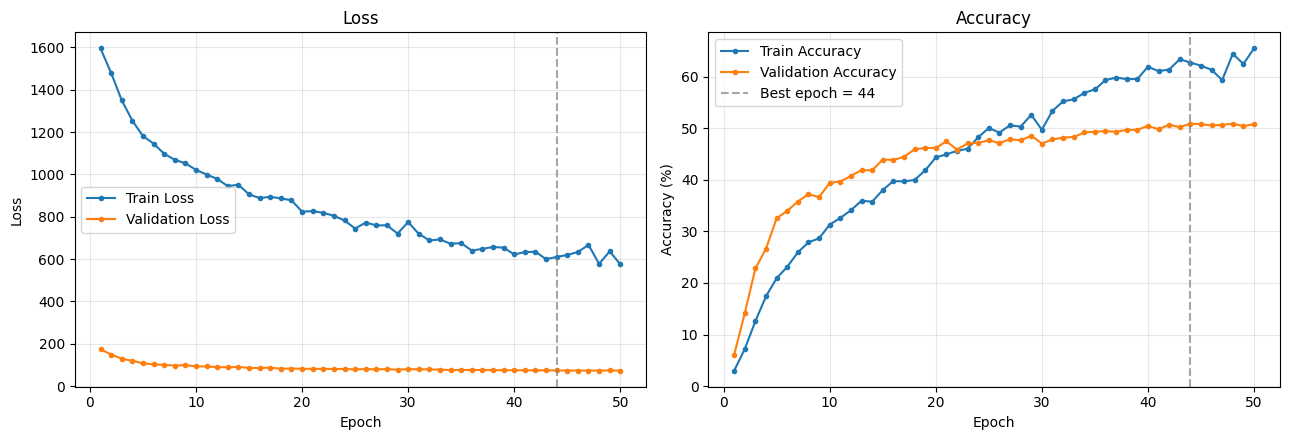

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(epoch_list, tr_loss_list, label='Train Loss', marker='o', markersize=3)
ax[0].plot(epoch_list, val_loss_list, label='Validation Loss', marker='o', markersize=3)
ax[0].set_title('Loss')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')
ax[0].grid(alpha=0.3)
ax[0].legend()

ax[1].plot(epoch_list, tr_acc_list, label='Train Accuracy', marker='o', markersize=3)
ax[1].plot(epoch_list, val_acc_list, label='Validation Accuracy', marker='o', markersize=3)
ax[1].set_title('Accuracy')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Accuracy (%)')
ax[1].grid(alpha=0.3)
ax[1].legend()

if best_epoch > 0:
    ax[0].axvline(best_epoch, color='gray', linestyle='--', alpha=0.7)
    ax[1].axvline(best_epoch, color='gray', linestyle='--', alpha=0.7, label=f'Best epoch = {best_epoch}')
    ax[1].legend()

plt.tight_layout()
plt.show()